# 01 · Team-Season Offensive & Defensive Breakdown

**Whiteboard project #1 — Year-to-year offense & defense breakdown: team level, run vs. pass, tendencies.**

This notebook builds the foundation every later project sits on:

1. Load play-by-play and check what data we actually have for each season (including the participation and FTN charting data that later projects need).
2. Define a clean set of offensive plays and a "neutral situation" filter.
3. Build **team-season offense and defense tables**: efficiency (EPA, success rate), run vs. pass splits, and tendencies (pass rate, pass rate over expected, shotgun, no-huddle).
4. Look at league-wide trends, which team stats are *stable* year to year, the biggest risers and fallers, and a single-team view.

Outputs are saved to `data/processed/` for the next notebooks.

## Setup

Imports, data paths, and a consistent chart style. Paths are relative to the `notebooks/` folder. Run `python -m src.ingest` from the repo root first if `data/raw/` is empty.

In [16]:
from pathlib import Path

import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_float_precision(3)

# Chart style: thin lines, recessive grid, one blue / one orange series
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1e", "#6b6a64", "#e4e2dc"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (11, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2, "lines.markersize": 5,
    "legend.frameon": False,
})


def season_line(ax, seasons, values, last_full, color, label=None, **kw):
    """Solid line through complete seasons; dashed segment + hollow dot for the in-progress season."""
    seasons, values = list(seasons), list(values)
    done = [(s, v) for s, v in zip(seasons, values) if s <= last_full]
    part = [(s, v) for s, v in zip(seasons, values) if s > last_full]
    ax.plot([s for s, _ in done], [v for _, v in done], color=color, marker="o", label=label, **kw)
    if part and done:
        ax.plot([done[-1][0], part[0][0]], [done[-1][1], part[0][1]], color=color, linestyle=":", linewidth=kw.get("linewidth", 2))
        ax.scatter([s for s, _ in part], [v for _, v in part], facecolors="white", edgecolors=color, s=40, zorder=3, linewidths=1.5)

## 1. Load play-by-play

nflverse play-by-play has ~370 columns; we only read the ones this notebook needs. Each season is its own parquet file, so we read them all and stack them.

In [17]:
PBP_COLS = [
    "season", "season_type", "week", "game_id", "play_id", "posteam", "defteam",
    "down", "ydstogo", "yardline_100", "qtr", "half_seconds_remaining", "wp",
    "play_type", "pass", "rush", "qb_scramble", "sack", "epa", "success", "yards_gained",
    "air_yards", "shotgun", "no_huddle", "xpass",
]

pbp_files = sorted((RAW / "pbp").glob("pbp_*.parquet"))
pbp = pl.concat([pl.read_parquet(f, columns=PBP_COLS) for f in pbp_files], how="diagonal_relaxed")

LATEST = pbp["season"].max()
latest_week = pbp.filter(pl.col("season") == LATEST)["week"].max()
print(f"{pbp.height:,} plays | seasons {pbp['season'].min()}–{LATEST} | {LATEST} is through week {latest_week}")

502,992 plays | seasons 2016–2026 | 2026 is through week 7


Plays per season, split by regular season vs. postseason. The most recent season is still in progress, so it will look short.

In [18]:
(pbp.group_by("season")
    .agg(
        plays=pl.len(),
        reg=(pl.col("season_type") == "REG").sum(),
        post=(pl.col("season_type") == "POST").sum(),
        max_week=pl.col("week").max(),
    )
    .sort("season"))

season,plays,reg,post,max_week
i32,u32,u32,u32,i32
2016,47651,45707,1944,21
2017,47245,45268,1977,21
2018,47109,45120,1989,21
2019,47260,45339,1921,21
2020,47705,45406,2299,21
2021,49922,47651,2271,22
2022,49434,47157,2277,22
2023,49665,47399,2266,22
2024,49492,47274,2218,22


## 2. What data do we have, by season?

Later projects (personnel, formations, coverages, blitzes) depend on two extra sources, and their coverage is uneven:

- **Participation** (`participation/`): personnel groupings, formation, defenders in the box, pass rushers, coverage type, routes. Published 2016–2025.
- **FTN charting** (`ftn_charting/`): play action, RPO, screens, motion, number of blitzers. Published 2022–present.

This table shows the share of rows with a value for each field, so we know which questions each season can answer.

In [19]:
def fill_rates(folder, fields):
    files = sorted((RAW / folder).glob(f"{folder}_*.parquet"))
    rows = []
    for f in files:
        season = int(f.stem.split("_")[-1])
        df = pl.read_parquet(f)
        row = {"season": season, "rows": df.height}
        for c in fields:
            row[c] = (1 - df[c].null_count() / df.height) if c in df.columns else None
        rows.append(row)
    return pl.DataFrame(rows).sort("season")

participation_fill = fill_rates(
    "participation",
    ["offense_personnel", "defense_personnel", "offense_formation", "defenders_in_box",
     "number_of_pass_rushers", "defense_man_zone_type", "defense_coverage_type", "route"],
)
participation_fill

season,rows,offense_personnel,defense_personnel,offense_formation,defenders_in_box,number_of_pass_rushers,defense_man_zone_type,defense_coverage_type,route
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
2016,48434,0.759,0.759,0.723,0.737,0.419,0.000,0.000,0.387
2017,47998,0.757,0.757,0.723,0.738,0.408,0.000,0.000,0.374
2018,47875,0.760,0.760,0.721,0.736,0.432,0.384,0.384,0.374
2019,48034,0.761,0.761,0.731,0.742,0.433,0.385,0.385,0.370
2020,48513,0.761,0.761,0.731,0.744,0.435,0.390,0.390,0.375
2021,50714,0.763,0.763,0.730,0.744,0.433,0.387,0.387,0.373
2022,50150,0.762,0.762,0.734,0.744,0.427,0.378,0.378,0.362
2023,46168,1.000,1.000,0.801,1.000,0.972,1.000,0.496,1.000
2024,45919,1.000,1.000,0.799,1.000,1.000,1.000,0.488,1.000


Coverage labels only apply to pass plays, so a ~40–50% fill rate across *all* plays can still mean near-complete coverage of dropbacks. Join participation to the play-by-play to check that directly.

In [20]:
part = pl.concat(
    [pl.read_parquet(f, columns=["nflverse_game_id", "play_id", "defense_coverage_type", "defense_man_zone_type"])
     for f in sorted((RAW / "participation").glob("participation_*.parquet"))],
    how="diagonal_relaxed",
).rename({"nflverse_game_id": "game_id"})

dropbacks = pbp.filter((pl.col("season_type") == "REG") & (pl.col("pass") == 1))
(dropbacks.join(part, on=["game_id", "play_id"], how="left")
    .group_by("season")
    .agg(
        dropbacks=pl.len(),
        has_coverage_type=pl.col("defense_coverage_type").is_not_null().mean(),
        has_man_zone=pl.col("defense_man_zone_type").is_not_null().mean(),
    )
    .sort("season"))

season,dropbacks,has_coverage_type,has_man_zone
i32,u32,f64,f64
2016,21271,0.000,0.000
2017,20589,0.000,0.000
2018,20926,0.837,0.837
2019,21191,0.836,0.836
2020,21067,0.849,0.849
2021,22075,0.843,0.843
2022,21373,0.841,0.841
2023,21885,0.996,1.000
2024,21455,0.998,1.000


FTN charting: rows per season and how often the blitz / play-action fields are filled.

In [21]:
fill_rates("ftn_charting", ["is_play_action", "is_rpo", "is_screen_pass", "is_motion", "n_blitzers", "n_pass_rushers"])

season,rows,is_play_action,is_rpo,is_screen_pass,is_motion,n_blitzers,n_pass_rushers
i64,i64,f64,f64,f64,f64,f64,f64
2022,41643,1.000,1.000,1.000,1.000,1.000,1.000
2023,48225,1.000,1.000,1.000,1.000,1.000,0.971
2024,48031,1.000,1.000,1.000,1.000,1.000,1.000
2025,47316,1.000,1.000,1.000,1.000,1.000,1.000
2026,18019,1.000,1.000,1.000,1.000,1.000,1.000


## 3. Define the play set

Standard nflverse conventions:

- **Regular season only** for team-season comparisons (playoff samples are tiny and uneven across teams).
- A **play** is any dropback (`pass == 1`, which includes sacks and scrambles) or designed run (`rush == 1`), with a valid EPA. This excludes kicks, punts, kneels, spikes and penalties-only plays.
- **Neutral situations** strip out game-script effects when measuring tendencies: 1st/2nd down, win probability 20–80%, and more than two minutes left in the half.
- **Explosive** plays: dropbacks of 20+ yards or runs of 10+ yards.

In [22]:
plays = (
    pbp.filter(
        (pl.col("season_type") == "REG")
        & ((pl.col("pass") == 1) | (pl.col("rush") == 1))
        & pl.col("epa").is_not_null()
        & pl.col("posteam").is_not_null()
    )
    .with_columns(
        neutral=((pl.col("down") <= 2) & pl.col("wp").is_between(0.2, 0.8) & (pl.col("half_seconds_remaining") > 120)),
        explosive=(((pl.col("pass") == 1) & (pl.col("yards_gained") >= 20)) | ((pl.col("rush") == 1) & (pl.col("yards_gained") >= 10))),
        pass_over_expected=pl.col("pass") - pl.col("xpass"),
    )
)
print(f"{plays.height:,} offensive plays, {plays['neutral'].mean():.0%} in neutral situations")

358,146 offensive plays, 43% in neutral situations


## 4. Team-season tables

One function builds both sides. For **offense** the team is `posteam`; for **defense** it's `defteam`, and every number is what that defense *allowed* (or faced, for tendencies). Ranks are within each season: 1 = best (highest EPA for offense, lowest EPA allowed for defense).

| column | meaning |
|---|---|
| `epa_per_play` | expected points added per play |
| `success_rate` | share of plays with positive EPA |
| `pass_epa`, `rush_epa` | EPA per dropback / per designed run |
| `pass_rate` | share of plays that were dropbacks (all situations) |
| `neutral_pass_rate` | dropback share in neutral situations: the cleanest read on play-calling identity |
| `proe` | pass rate over expected in neutral situations (vs. nflverse's `xpass` model) |
| `explosive_rate` | share of plays that were explosive |
| `shotgun_rate`, `no_huddle_rate` | formation / tempo tendencies |

In [23]:
def team_season(df: pl.DataFrame, side: str) -> pl.DataFrame:
    team_col = "posteam" if side == "off" else "defteam"
    neutral = pl.col("neutral")
    is_pass, is_rush = pl.col("pass") == 1, pl.col("rush") == 1
    out = (
        df.group_by(["season", team_col])
        .agg(
            plays=pl.len(),
            epa_per_play=pl.col("epa").mean(),
            success_rate=pl.col("success").mean(),
            pass_epa=pl.col("epa").filter(is_pass).mean(),
            rush_epa=pl.col("epa").filter(is_rush).mean(),
            pass_success=pl.col("success").filter(is_pass).mean(),
            rush_success=pl.col("success").filter(is_rush).mean(),
            pass_rate=pl.col("pass").mean(),
            neutral_pass_rate=pl.col("pass").filter(neutral).mean(),
            proe=pl.col("pass_over_expected").filter(neutral).mean(),
            explosive_rate=pl.col("explosive").mean(),
            shotgun_rate=pl.col("shotgun").mean(),
            no_huddle_rate=pl.col("no_huddle").mean(),
        )
        .rename({team_col: "team"})
    )
    better_high = side == "off"
    return out.with_columns(
        epa_rank=pl.col("epa_per_play").rank("min", descending=better_high).over("season").cast(pl.Int32),
        pass_epa_rank=pl.col("pass_epa").rank("min", descending=better_high).over("season").cast(pl.Int32),
        rush_epa_rank=pl.col("rush_epa").rank("min", descending=better_high).over("season").cast(pl.Int32),
    ).sort(["season", "epa_rank"])

offense = team_season(plays, "off")
defense = team_season(plays, "def")

offense.write_parquet(PROCESSED / "team_season_offense.parquet")
defense.write_parquet(PROCESSED / "team_season_defense.parquet")
print(f"offense: {offense.shape}, defense: {defense.shape} -> saved to {PROCESSED}")

offense: (352, 18), defense: (352, 18) -> saved to ../data/processed


Top 10 offenses of the most recent **complete** season.

In [24]:
LAST_FULL = LATEST if latest_week >= 18 else LATEST - 1
offense.filter(pl.col("season") == LAST_FULL).head(10).select(
    "team", "epa_rank", "epa_per_play", "success_rate", "pass_epa", "rush_epa",
    "neutral_pass_rate", "proe", "explosive_rate",
)

team,epa_rank,epa_per_play,success_rate,pass_epa,rush_epa,neutral_pass_rate,proe,explosive_rate
str,i32,f64,f64,f64,f64,f64,f64,f64
"""NE""",1,0.157,0.484,0.309,-0.084,0.566,0.039,0.105
"""LA""",2,0.149,0.522,0.235,0.021,0.585,0.062,0.114
"""BUF""",3,0.140,0.486,0.219,0.039,0.512,-0.017,0.109
"""GB""",4,0.124,0.482,0.276,-0.076,0.497,-0.043,0.103
"""DAL""",5,0.111,0.473,0.180,-0.008,0.522,-0.004,0.083
"""SF""",6,0.090,0.485,0.173,-0.033,0.545,0.014,0.082
"""IND""",7,0.080,0.465,0.097,0.054,0.557,0.023,0.080
"""CHI""",8,0.076,0.457,0.119,0.011,0.531,0.003,0.101
"""DET""",9,0.072,0.450,0.167,-0.068,0.490,-0.056,0.101


Top 10 defenses of the same season (lowest EPA allowed per play).

In [25]:
defense.filter(pl.col("season") == LAST_FULL).head(10).select(
    "team", "epa_rank", "epa_per_play", "success_rate", "pass_epa", "rush_epa", "explosive_rate",
)

team,epa_rank,epa_per_play,success_rate,pass_epa,rush_epa,explosive_rate
str,i32,f64,f64,f64,f64,f64
"""SEA""",1,-0.111,0.401,-0.061,-0.207,0.057
"""HOU""",2,-0.109,0.395,-0.097,-0.129,0.069
"""MIN""",3,-0.085,0.417,-0.086,-0.085,0.074
"""CLE""",4,-0.085,0.408,-0.091,-0.078,0.081
"""JAX""",5,-0.080,0.423,-0.067,-0.108,0.067
"""LAC""",6,-0.076,0.416,-0.051,-0.117,0.078
"""LA""",7,-0.067,0.419,-0.049,-0.098,0.078
"""DEN""",8,-0.060,0.377,-0.037,-0.105,0.057
"""PHI""",9,-0.050,0.426,-0.016,-0.101,0.083


## 5. League-wide trends

How the league as a whole has shifted. The latest season is still in progress, so it's drawn with a dotted line and a hollow dot. Passing and rushing EPA share one axis because they're the same unit.

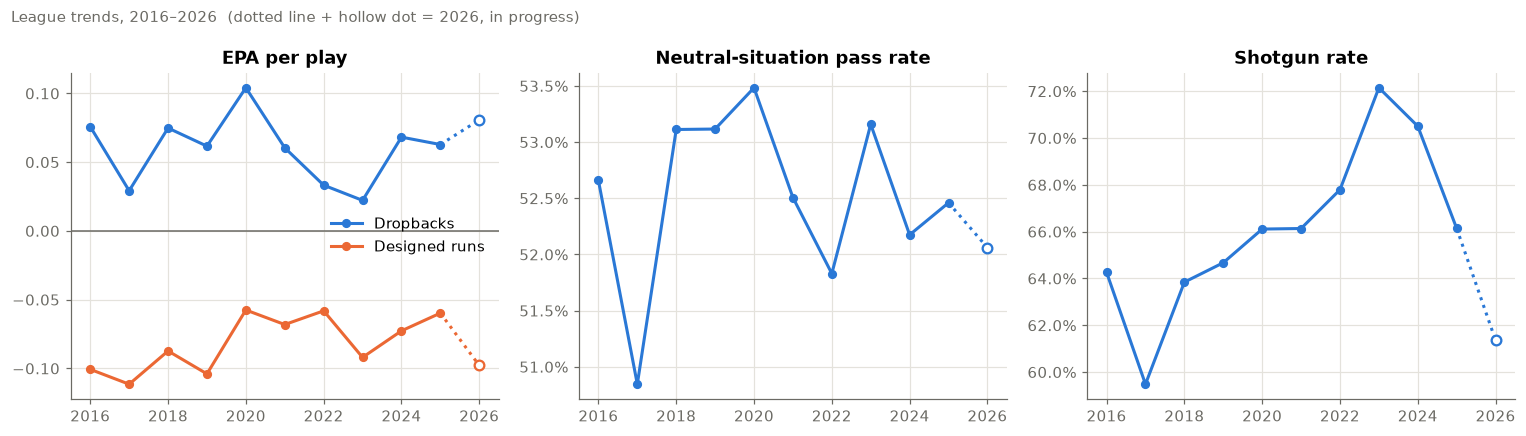

season,epa_per_play,pass_epa,rush_epa,neutral_pass_rate,shotgun_rate,success_rate
i32,f64,f64,f64,f64,f64,f64
2016,0.010,0.076,-0.101,0.527,0.643,0.436
2017,-0.025,0.029,-0.111,0.508,0.595,0.419
2018,0.014,0.075,-0.087,0.531,0.638,0.444
2019,-0.000,0.062,-0.104,0.531,0.647,0.433
2020,0.043,0.104,-0.058,0.535,0.661,0.458
2021,0.012,0.060,-0.068,0.525,0.661,0.445
2022,-0.003,0.033,-0.058,0.518,0.678,0.440
2023,-0.021,0.022,-0.092,0.532,0.721,0.430
2024,0.013,0.068,-0.073,0.522,0.705,0.441


In [26]:
league = (
    plays.group_by("season")
    .agg(
        epa_per_play=pl.col("epa").mean(),
        pass_epa=pl.col("epa").filter(pl.col("pass") == 1).mean(),
        rush_epa=pl.col("epa").filter(pl.col("rush") == 1).mean(),
        neutral_pass_rate=pl.col("pass").filter(pl.col("neutral")).mean(),
        shotgun_rate=pl.col("shotgun").mean(),
        success_rate=pl.col("success").mean(),
    )
    .sort("season")
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

ax = axes[0]
season_line(ax, league["season"], league["pass_epa"], LAST_FULL, BLUE, "Dropbacks")
season_line(ax, league["season"], league["rush_epa"], LAST_FULL, ORANGE, "Designed runs")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_title("EPA per play")
ax.legend(loc="center right")

ax = axes[1]
season_line(ax, league["season"], league["neutral_pass_rate"], LAST_FULL, BLUE)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_title("Neutral-situation pass rate")

ax = axes[2]
season_line(ax, league["season"], league["shotgun_rate"], LAST_FULL, BLUE)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_title("Shotgun rate")

for ax in axes:
    ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
fig.suptitle(f"League trends, {league['season'].min()}–{LATEST}  (dotted line + hollow dot = {LATEST}, in progress)", x=0.01, ha="left", color=MUTED, fontsize=10)
fig.tight_layout()
plt.show()

league

## 6. Which team stats carry over year to year?

Before reading anything into a team's change from one season to the next, it helps to know which stats are *sticky* (a real team trait) and which are mostly noise. For each metric we correlate a team's value in season N with its value in season N+1, across all complete seasons.

Tendencies like pass rate tend to be far more stable than efficiency, and defense tends to be less stable than offense — this checks how true that is in this data.

In [27]:
METRICS = ["epa_per_play", "success_rate", "pass_epa", "rush_epa", "neutral_pass_rate",
           "proe", "explosive_rate", "shotgun_rate", "no_huddle_rate"]

def year_over_year(table: pl.DataFrame, side: str) -> pl.DataFrame:
    t = table.filter(pl.col("season") <= LAST_FULL)
    nxt = t.select(["team", (pl.col("season") - 1).alias("season"), *[pl.col(m).alias(f"{m}_next") for m in METRICS]])
    pairs = t.join(nxt, on=["team", "season"], how="inner")
    return pl.DataFrame({
        "metric": METRICS,
        f"{side}_yoy_r": [pairs.select(pl.corr(m, f"{m}_next")).item() for m in METRICS],
    })

stability = year_over_year(offense, "off").join(year_over_year(defense, "def"), on="metric")
stability.sort("off_yoy_r", descending=True)

metric,off_yoy_r,def_yoy_r
str,f64,f64
"""shotgun_rate""",0.665,0.442
"""no_huddle_rate""",0.563,0.256
"""neutral_pass_rate""",0.421,0.167
"""proe""",0.400,0.188
"""pass_epa""",0.394,0.241
"""epa_per_play""",0.389,0.262
"""success_rate""",0.379,0.247
"""rush_epa""",0.336,0.241
"""explosive_rate""",0.296,0.304


## 7. Biggest year-to-year movers

Change in offensive and defensive EPA per play from the prior season, for the latest complete season. For defense, a **negative** change is an improvement (less EPA allowed).

In [28]:
def movers(table: pl.DataFrame, season: int) -> pl.DataFrame:
    cur = table.filter(pl.col("season") == season).select("team", "epa_per_play", "epa_rank")
    prev = table.filter(pl.col("season") == season - 1).select(
        "team", pl.col("epa_per_play").alias("prev_epa"), pl.col("epa_rank").alias("prev_rank"))
    return (cur.join(prev, on="team")
               .with_columns(change=pl.col("epa_per_play") - pl.col("prev_epa"),
                             rank_change=pl.col("prev_rank") - pl.col("epa_rank"))
               .sort("change", descending=True))

off_moves = movers(offense, LAST_FULL)
def_moves = movers(defense, LAST_FULL)

print(f"Offense, {LAST_FULL - 1} -> {LAST_FULL}: biggest improvements")
display(off_moves.head(5))
print("Biggest declines")
display(off_moves.tail(5))
print(f"Defense, {LAST_FULL - 1} -> {LAST_FULL}: biggest improvements (EPA allowed fell)")
display(def_moves.sort("change").head(5))

Offense, 2024 -> 2025: biggest improvements


team,epa_per_play,epa_rank,prev_epa,prev_rank,change,rank_change
str,f64,i32,f64,i32,f64,i32
"""NE""",0.157,1,-0.079,27,0.236,26
"""DAL""",0.111,5,-0.090,28,0.201,23
"""CHI""",0.076,8,-0.075,26,0.150,18
"""NYG""",0.044,10,-0.092,29,0.136,19
"""IND""",0.080,7,-0.047,24,0.128,17


Biggest declines


team,epa_per_play,epa_rank,prev_epa,prev_rank,change,rank_change
str,f64,i32,f64,i32,f64,i32
"""WAS""",0.034,16,0.139,4,-0.106,-12
"""NYJ""",-0.124,29,0.001,17,-0.125,-12
"""TB""",0.002,20,0.132,5,-0.130,-15
"""MIN""",-0.094,28,0.037,14,-0.131,-14
"""BAL""",0.037,15,0.197,1,-0.160,-14


Defense, 2024 -> 2025: biggest improvements (EPA allowed fell)


team,epa_per_play,epa_rank,prev_epa,prev_rank,change,rank_change
str,f64,i32,f64,i32,f64,i32
"""JAX""",-0.080,5,0.127,31,-0.207,26
"""NE""",-0.041,11,0.083,30,-0.124,19
"""LA""",-0.067,7,0.050,23,-0.117,16
"""CLE""",-0.085,4,0.017,18,-0.102,14
"""CAR""",0.060,23,0.154,32,-0.094,9


## 8. Offense vs. defense map

Every team in the latest complete season. Up and to the right is good on both sides: the defensive axis is flipped so that allowing *less* EPA plots higher. Dashed lines are league averages.

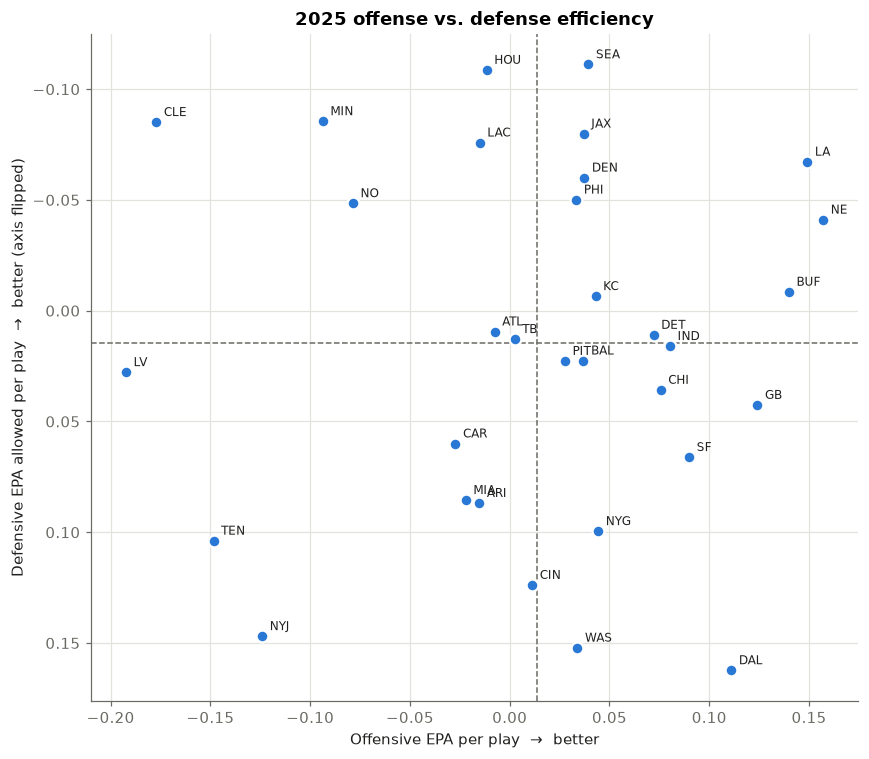

In [29]:
o = offense.filter(pl.col("season") == LAST_FULL).select("team", pl.col("epa_per_play").alias("off_epa"))
d = defense.filter(pl.col("season") == LAST_FULL).select("team", pl.col("epa_per_play").alias("def_epa"))
od = o.join(d, on="team")

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(od["off_epa"], od["def_epa"], s=60, color=BLUE, edgecolors="white", linewidths=1.5, zorder=3)
for team, x, y in od.iter_rows():
    ax.annotate(team, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK)
ax.axvline(od["off_epa"].mean(), color=MUTED, linestyle="--", linewidth=1)
ax.axhline(od["def_epa"].mean(), color=MUTED, linestyle="--", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Offensive EPA per play  →  better")
ax.set_ylabel("Defensive EPA allowed per play  →  better (axis flipped)")
ax.set_title(f"{LAST_FULL} offense vs. defense efficiency")
plt.tight_layout()
plt.show()

## 9. Single-team view

Change `TEAM` to any abbreviation to see that team's year-to-year profile next to the league average.

Reading the charts: **higher on the chart is always better.** Offensive EPA is good when positive. Defensive EPA is what the defense *allowed*, so negative is good — that axis is flipped so a strong defense plots high, the same way as the offense vs. defense map above. In the table, a negative `def_epa` and a low `def_rank` mean a good defense.

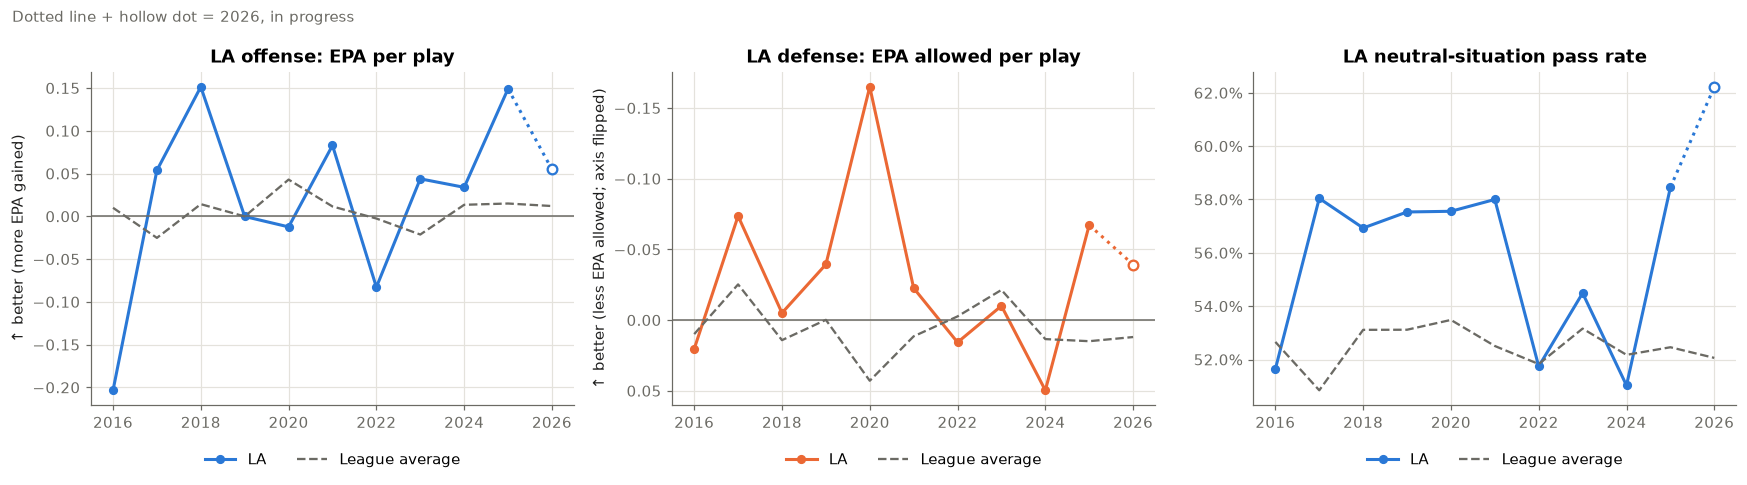

season,epa_rank,epa_per_play,pass_epa,rush_epa,neutral_pass_rate,proe,shotgun_rate,def_rank,def_epa
i32,i32,f64,f64,f64,f64,f64,f64,i32,f64
2016,32,-0.203,-0.222,-0.172,0.516,0.007,0.605,19,0.020
2017,6,0.054,0.131,-0.050,0.580,0.061,0.428,7,-0.074
2018,3,0.151,0.207,0.065,0.569,0.036,0.395,12,-0.005
2019,19,-0.000,0.086,-0.158,0.575,0.049,0.443,9,-0.039
2020,23,-0.012,0.033,-0.081,0.576,0.054,0.428,1,-0.165
2021,8,0.083,0.184,-0.089,0.580,0.041,0.585,9,-0.023
2022,29,-0.083,-0.094,-0.065,0.517,-0.017,0.534,22,0.016
2023,9,0.044,0.087,-0.020,0.545,0.014,0.620,20,-0.010
2024,15,0.034,0.107,-0.071,0.510,-0.008,0.556,23,0.050


In [34]:
TEAM = "LA"

t_off = offense.filter(pl.col("team") == TEAM).sort("season")
t_def = defense.filter(pl.col("team") == TEAM).sort("season")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
season_line(ax, t_off["season"], t_off["epa_per_play"], LAST_FULL, BLUE, TEAM)
ax.plot(league["season"], league["epa_per_play"], color=MUTED, linestyle="--", linewidth=1.5, label="League average")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_title(f"{TEAM} offense: EPA per play")
ax.set_ylabel("↑ better (more EPA gained)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)

ax = axes[1]
season_line(ax, t_def["season"], t_def["epa_per_play"], LAST_FULL, ORANGE, TEAM)
ax.plot(league["season"], league["epa_per_play"], color=MUTED, linestyle="--", linewidth=1.5, label="League average")
ax.axhline(0, color=MUTED, linewidth=1)
ax.invert_yaxis()
ax.set_title(f"{TEAM} defense: EPA allowed per play")
ax.set_ylabel("↑ better (less EPA allowed; axis flipped)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)

ax = axes[2]
season_line(ax, t_off["season"], t_off["neutral_pass_rate"], LAST_FULL, BLUE, TEAM)
ax.plot(league["season"], league["neutral_pass_rate"], color=MUTED, linestyle="--", linewidth=1.5, label="League average")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_title(f"{TEAM} neutral-situation pass rate")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)

fig.suptitle(f"Dotted line + hollow dot = {LATEST}, in progress", x=0.01, ha="left", color=MUTED, fontsize=10)

for ax in axes:
    ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
fig.tight_layout()
plt.show()

t_off.select("season", "epa_rank", "epa_per_play", "pass_epa", "rush_epa", "neutral_pass_rate", "proe", "shotgun_rate").join(
    t_def.select("season", pl.col("epa_rank").alias("def_rank"), pl.col("epa_per_play").alias("def_epa")), on="season")

## Next

- **02 · Personnel & concepts:** join participation and FTN charting to break offense down by personnel grouping, formation, play action / RPO / screens, and defense by personnel, box count, blitz rate and coverage (whiteboard project #2).
- That sets up the matchup questions: which concepts beat which coverages and blitzes, and the reverse.